## ABC renewal

Here we want to show how the interaction between contextual inference and context-specific priors come together to enable strong action recovery when presented with novel or ambigues cues, especially when context is uncertain. 

From Proposal:

Relapse after extinction (cue reactivity)

Illustrating how shifts in inferred context can re-express previously learned policies, leading to strong recovery of action.
-	The idea was to learn ‘drug cue and use action’ in A, extinction in B. Then C is an ambiguous context, e.g. mix of contexts or has slight cues in it, which would cause relapse. 
-	Here, ideally, we need ability to perceive cues. Also, not clear how we implement an ambiguous context exactly.

In animal experiments novel contexts are usually instantiated as a unique context C which is clearly perceivable as unique. 

If I let the agent learn cues, I do get ABC renewal. This effect however appears to be driven by the stronger extinction during B, not the higher rate of lever pressing. So this is not exactly what we are after. Write up like this and send to Stefan. 




## Classes

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.special as scp
import json
# import jsonpickle
from itertools import product
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
np.set_printoptions(suppress=True)


## Functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.special as scp
import json
from itertools import product
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scikit_posthocs as sp
from statannotations.Annotator import Annotator
from classes import Agent, MultiArmedBandit, World
from utilities import run_simulation
np.set_printoptions(suppress=True)
sns.set_style("whitegrid")
np.seterr(divide='ignore', invalid='ignore')
np.seterr(over='ignore', invalid='ignore')


def create_long_df_ABC(world, p):
	agent = world.agent
	TAU = p["TAU"]
	T = p["T"]

	run_arr = np.full(TAU * T, p["rep"])
	tau_arr = np.repeat(np.arange(TAU), T)
	t_arr = np.tile(np.arange(T), TAU)
	observation_arr = world.environment.observations.flatten()
	reward_arr = world.environment.rewards.flatten()
	action_arr = np.full((TAU,T), np.nan) 
	action_arr[:,0] = world.environment.actions[:,0]
	action_arr = action_arr.flatten()
	h_arr = np.full(TAU * T, p["h"])
	context_volatility_arr = np.full(TAU * T, p["context_volatility"])
	utility_0_arr = np.full(TAU * T, p["utility"][0])
	utility_1_arr = np.full(TAU * T, p["utility"][1])
	utility_2_arr = np.full(TAU * T, p["utility"][2])
	n_blocks = TAU // p["block_size"]
	block_arr = np.arange(p["blocks_per_context"].sum()).repeat(p["block_size"] * T)
	sim_arr = np.full(TAU*T,p["sim"])
	true_context = world.environment.training_protocol.repeat(2)
	habits = np.argmax(world.agent.prior_policies[-1,-1],axis=0)
	habit_c1 = np.full(TAU*T, habits[0])
	habit_c2 = np.full(TAU*T, habits[1])
	habit_c3 = np.full(TAU*T, habits[2])
	# Policy arrays
	prior_arr = {}
	likelihood_arr = {}
	posterior_arr = {}
	context_post_arr = {}
	policy_ent_arr = {}
	policy_surpr_arr = {}
	outcome_surp_arr = {}
	policy_post_arr = {}
	reward_prior_arr = {}

	inferred_context = np.argmax(agent.posterior_context[:,0,:],axis=1)
	nic = np.unique(inferred_context).size
	best_fit = 0
	best_mapping = []

	if nic == 2:
		failed = True
		best_mapping = np.unique(inferred_context)
		best_mapping = np.append(best_mapping, np.setdiff1d(np.arange(p["nc"]), best_mapping)[0])
	else:
		failed = False
		for i in range(100):
			mapping = np.random.permutation(p["nc"])
			fit = (mapping[inferred_context] == world.environment.training_protocol).sum()
			if fit > best_fit:
				best_fit = fit
				best_mapping = mapping

	# for c in range(nc):
	for ci, c in enumerate(best_mapping):
		context_post_arr[f"posterior_context_c{ci}"] = agent.posterior_context[:,:,c].flatten()
		policy_ent_arr[f"policy_entropy_c{ci}"] = agent.policy_entropy[:,:,c].flatten()
		policy_surpr_arr[f"policy_surprise_c{ci}"] = agent.policy_surprise[:,:,c].flatten()
		outcome_surp_arr[f"outcome_surprise_c{ci}"] = agent.outcome_surprise[:,:,c].flatten()
		
		for pi in range(p["npi"]):
			reward_prior_arr[f"reward_s{pi}_c{ci}"] = agent.prior_rewards[:,:,1,pi,c].flatten()
			prior_arr[f"prior_pi{pi}_c{ci}"] = agent.prior_policies[:,:,pi,c].flatten()
			likelihood_arr[f"likelihood_pi{pi}_c{ci}"] = agent.likelihood_policies[:,:,pi,c].flatten()
			posterior_arr[f"posterior_pi{pi}_c{ci}"] = agent.posterior_policies[:,:,pi,c].flatten()
	
	action_likelihood = np.einsum("dtpc,dtc-> dtp", agent.posterior_policies, agent.posterior_context)
	
	for pi in range(p["npi"]):
		policy_post_arr[f"posterior_pi{pi}"] = action_likelihood[:,:,pi].flatten()

	# Create dict
	long_df_dict = {
		"run": run_arr,
		"tau": tau_arr,
		"t": t_arr,
		"observation": observation_arr,
		"action": action_arr,
		"reward": reward_arr,
		"block": block_arr,
		"h": h_arr,
		"context_volatility": context_volatility_arr,
		"utility_0": utility_0_arr,
		"utility_1": utility_1_arr,
		"utility_2": utility_2_arr,
		"sim":sim_arr,
		"true_context":true_context,
		"failed": np.array([failed]).repeat(TAU*T),
		"habit_c1": habit_c1,
		"habit_c2": habit_c2,
		"habit_c3": habit_c3,
		**prior_arr,
		**likelihood_arr,
		**posterior_arr,
		**context_post_arr,
		**policy_ent_arr,
		**policy_surpr_arr,
		**outcome_surp_arr,
		**policy_post_arr,
		**reward_prior_arr
	}

	return pd.DataFrame(long_df_dict)


def plot_figures(df_long, p, dpi=100, title=""):
	print(df_long["h"])
	df_long["h"] = 1/df_long["h"]
	df_long["h"] = df_long["h"].astype("category")

	# failed_agents = df_long[df_long["habit_c2"]== 0].index
	# df_long = df_long.drop(failed_agents)

	nc = df_long.true_context.unique().size
	nh = df_long.h.unique()
	legend_titles = ["context A\n(training)", "context B\n(extinction)", "context C\n(test)"]

	# """ OBSEVATION MAPPING PLOT"""
	# plt.figure(figsize=(4,3),dpi=dpi)
	# g=sns.heatmap(prior_color_cue/prior_color_cue.sum(axis=0),annot=True)
	# g.set_title(f"p(cue|context) with \ncontext self-transition prob: {p["context_volatility"]}")


	""" PLOT CONTEXT POSTERIOR """
	# fig, axes = plt.subplots(1,k.size, figsize=(11,3),dpi=dpi)
	# plt.tight_layout()
	# # fig, axes = plt.subplots(2,5, figsize=(10,6))
	# for ai, ax in enumerate(axes):
	# 	for ci in range(nc):
	# 		g = sns.lineplot(ax=ax, data=df_long.query(f"t==0 & h == {k[ai]}"), x="tau", y=f"posterior_context_c{ci}", errorbar="se",label=legend_titles[ci])
	# 	if ai == axes.size-1:
	# 		g.legend(bbox_to_anchor=(1.05,1))
	# 	else:
	# 		g.legend_=None
	# 	ax.set_title(fr"$h$: {k[ai]}",fontsize=16)
	# 	ax.set_ylabel("Posterior contexts",fontsize=16)
	# 	ax.set_ylim([0,1])
	# 	ax.set_xlabel("trial")


	fig, axes = plt.subplots(1,nc, figsize=(9,3),dpi=dpi)
	plt.tight_layout()
	plt.subplots_adjust(wspace=0.3)

	legend_titles = ["context A\n(training)", "context B\n(extinction)", "context C\n(test)"]
	for ai, ax in enumerate(axes):
		sns.lineplot(ax=ax, data=df_long.query(f"t==0"), x="tau", y=f"posterior_context_c{ai}", hue="h",errorbar="se", palette="viridis")
		ax.set_title(legend_titles[ai],fontsize=16)
		if ai == axes.size-1:
			ax.legend(bbox_to_anchor=(1.05,1), title=r"$h$")
		else:
			ax.legend_=None
		# ax.set_title(fr"$h$: {k[ai]}",fontsize=16)
		ax.set_ylabel("Posterior context",fontsize=16)
		ax.set_ylim([0,1.01])
		ax.set_xlabel("trial", fontsize=16)


	""" PLOT LEVER PRESS POSTERIOR"""
	df_long["posterior_entropy"] = -np.nansum(df_long[[f"posterior_context_c{c}" for c in range(p["nc"])]] \
	                                          * np.log(df_long[[f"posterior_context_c{c}" for c in range(p["nc"])]] + 1e-10), axis=1
											  )
	
	fig, axes = plt.subplots(1,2, figsize=(8,3),dpi=dpi)
	plt.tight_layout()
	plt.subplots_adjust(wspace=0.3)

	ax = axes[0]
	plt.figure(dpi=dpi)
	sns.lineplot(ax=ax, data=df_long.query("t==0"), x="tau", y="posterior_entropy", hue="h", errorbar="se", palette="viridis", linewidth=0.5)
	# ax.set_xlim([158,165])
	# ax.set_ylim([0.5,0.65])
	ax.set_ylabel("Context posterior entropy", fontsize=16)
	ax.set_xlabel(r"trial", fontsize=16)

	ax = axes[1]
	g = sns.lineplot(ax=ax, data=df_long.query(f"t==0"), x="tau", y=f"posterior_pi{0}", hue="h", errorbar="se",linewidth=0.5, palette="viridis")
	# ax.set_ylim([0.25,0.4])
	# ax.set_xlim([158,165])
	ax.legend(loc="lower left",title=r"$h$")
	ax.set_ylabel("Posterior of lever press policy",fontsize=16)
	ax.set_xlabel("trial",fontsize=16)
	
	"""ACTION 1 FREQUENCY PLOT """

	plot_df = df_long.copy()
	plot_df["action"] = plot_df["action"].astype("category")
	plot_df = plot_df.groupby(by=["h","run", "block","t"])["action"].value_counts(normalize=True, dropna=False).reset_index()

	plot_df = plot_df.query("action==0 & block >= 7 & t==0")
	# display(plot_df)

	plt.figure(figsize=(4,3), dpi=dpi) 
	# palette = sns.color_palette("tab10")
	# palette = sns.color_palette("tab10")[1:] + sns.color_palette("tab10")[:1]
	palette = "Grays"
	# g = sns.boxplot(data=plot_df.query("action==0 & block >= 7"), x="h",y="proportion", hue="block", palette="tab10", boxprops={"alpha":0.6})
	g = sns.barplot(data=plot_df, x="h",y="proportion", hue="block", palette=palette, alpha=0.7, linewidth=0.6,edgecolor="black")
	g = sns.stripplot(data=plot_df, x="h",y="proportion", hue="block",dodge=True,palette=palette, linewidth=0.5, edgecolor="black", alpha=0.8,size=2)

	g.legend(handles=g.get_legend_handles_labels()[0], labels=["context B (extinction)", "context C (test)"], fontsize=16, title=None, loc="upper left")
	g.set_ylabel("\nAmount of lever pressing", fontsize=16)
	g.set_xlabel(None)
	g.set_xticklabels([h.replace(" ", "\n") for h in h_order],fontsize=16)
	g.set_title(title, fontsize=16)
	g.set_ylim([0,1])
 
	"""   Learned policy prior    """
	
	# fig, axes = plt.subplots(1,nh.size, figsize=(16,2),dpi=dpi)

	# plt.subplots_adjust(wspace=0.35)
	# for ax,h in zip(axes, 1/nh.to_numpy()):
	# 	sns.heatmap(ax=ax, annot=True, data=prior_policies_matrix[h], vmin=0, vmax=1, cmap="Grays_r")
	# 	ax.set_title(fr"$h$: {1/h}", fontsize=14)
	# 	ax.set_ylabel("Policy", fontsize=14)
	# 	ax.set_xlabel("Context", fontsize=14)
	# fig.suptitle("Learned $p(\pi|c)$", fontsize=16, y=1.15)
	

	"""   ABC renewal magnitude    """


	df = df_long.copy()
	# df["action"] = df["action"].astype("category")
	# df = df.groupby(by=["h","run","block","t"])["action"].value_counts(normalize=True,dropna=False)
	# df = (df.loc[:,:,8,0,0] - df.loc[:,:,7,0,0]).to_frame()
	# # display(df.loc[np.isnan(df["proportion"])])
	# plt.figure(dpi=dpi)
	# g = sns.barplot(data=df, x="h",y="proportion", palette="viridis")
	# g = sns.stripplot(data=df, x="h", y="proportion", palette="viridis", linewidth=0.5, edgecolor="black", alpha=0.8,size=2)
	# g.set_ylim([0,1])
	# g.set_ylabel("Lever press difference\ncontext C - context A", fontsize=16)
	# g.set_xlabel(r"Habitual tendency $h$", fontsize=16)


	df = df.groupby(["h", "run", "block", "t"])["action"].value_counts(normalize=True, dropna=False)

	df = (df.loc[:,:,8,0,0] - df.loc[:,:,7,0,0]).to_frame().reset_index()

	# Check normality
	print("\nNormality (Shapiro-Wilk):")
	normal = True
	for h, g in df.groupby("h"):
		x = g["proportion"].dropna()
		W, p = stats.shapiro(x)
		print(f"  h={h}: W={W:.3f}, p={p:.4g}")
		normal &= p > 0.05

	groups = [g["proportion"].dropna() for _, g in df.groupby("h")]

	# Omnibus test + post-hoc
	if normal:
		stat, p = stats.f_oneway(*groups)
		print(f"\nOne-way ANOVA: F={stat:.3f}, p={p:.4g}")

		tukey = pairwise_tukeyhsd(df["proportion"], df["h"])
		print("\nTukey HSD:")

		inds = tukey._multicomp.pairindices
		pairs = [
			(tukey._multicomp.groupsunique[i],
			tukey._multicomp.groupsunique[j])
			for i, j in zip(*inds)
		]
		pvals = tukey.pvalues

	else:
		stat, p = stats.kruskal(*groups)
		print(f"\nKruskal-Wallis: H={stat:.3f}, p={p:.4g}")

		posthoc = sp.posthoc_dunn(df, val_col="proportion", group_col="h")

		print("\nDunn's post-hoc test:")
		print(posthoc)

		pairs = [
			(a, b)
			for i, a in enumerate(posthoc.index)
			for b in posthoc.columns[i + 1:]
		]
		pvals = [posthoc.loc[a, b] for a, b in pairs]


	plt.figure(figsize=(4,3), dpi=dpi)
	ax = sns.barplot(data=df, x="h", y="proportion", palette="viridis", errorbar="se")
	sns.stripplot(data=df, x="h", y="proportion", palette="viridis", linewidth=0.5, edgecolor="black", alpha=0.8, size=2)

	ax.set_ylim([0, 1])
	ax.set_ylabel("\nABC renewal", fontsize=16)
	ax.set_xlabel(None)
	ax.set_xticklabels([h.replace(" ", "\n") for h in h_order], fontsize=16)
	ax.set_title(title, fontsize=16)
	# significance stars
	annotator = Annotator(ax, pairs, data=df, x="h", y="proportion")
	annotator.configure(
		test=None,
		text_format="star",
		# loc="outside",
		verbose=0
	)
	annotator.set_pvalues_and_annotate(pvals)



just finished sim 0
0         1
1         1
2         1
3         1
4         1
       ... 
355    1000
356    1000
357    1000
358    1000
359    1000
Name: h, Length: 54000, dtype: int32


C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32904\3281147066.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df = plot_df.groupby(by=["h","run", "block","t"])["action"].value_counts(normalize=True, dropna=False).reset_index()
C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32904\3281147066.py:213: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  plot_df = plot_df.query("action==0 & block >= 7 & t==0")
C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32904\3281147066.py:224: UserWarning: Mismatched number of handles and labels: len(handles) = 4 len(labels) = 2
  g.legend(handles=g.get_legend_handles_labels()[0], labels=["context B (extinction)", "context C (test)"], fontsize=16, title=Non


Normality (Shapiro-Wilk):
  h=0.001: W=0.970, p=0.2286
  h=0.1: W=0.975, p=0.3517
  h=1.0: W=0.838, p=7.619e-06

Kruskal-Wallis: H=3.517, p=0.1723

Dunn's post-hoc test:
          0.001     0.100     1.000
0.001  1.000000  0.110723  0.954773
0.100  0.110723  1.000000  0.098602
1.000  0.954773  0.098602  1.000000


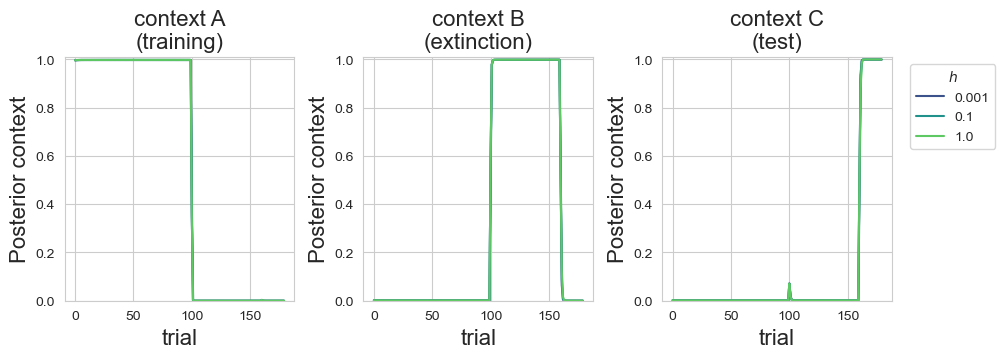

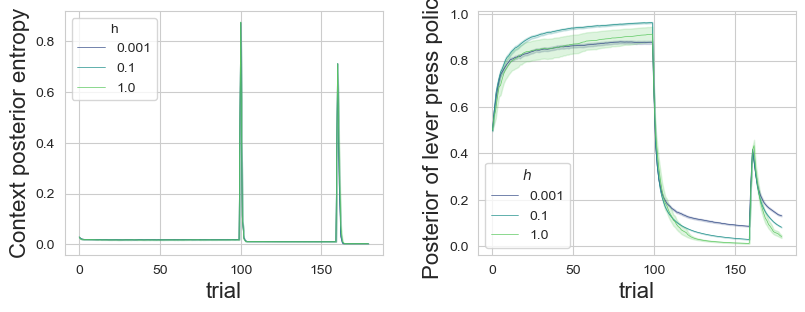

<Figure size 640x480 with 0 Axes>

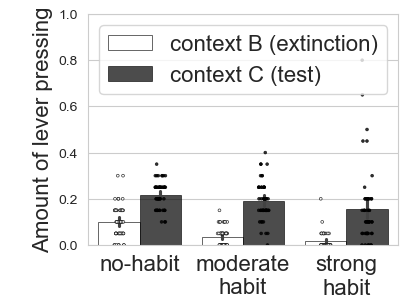

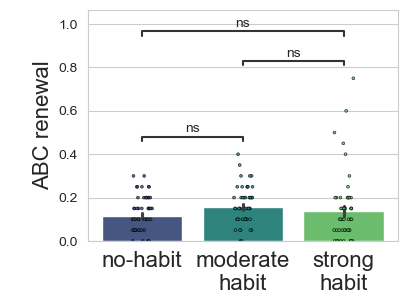

In [ ]:
dpi = 100

#############################################
# setup simulation run, agent, env parameters
############################################
np.random.seed(2)

h_order = ["no-habit", "moderate habit", "strong habit"]
env_order = ["low-certainty", "high-certainty"]

pars = {
	"na": 2,
	"nc": 3,
	"T":2,
	"nr":3,
	"hs": np.array([1,10,1000]),
	"context_volatility" : 0.98,
	"block_size" : 20,
	"utility" : np.array([0.025,0.95,0.025]),
	"nsims" : 50,
	"learn_cues" : True,
	"debug" : False,
}

pars["blocks_per_context"] = np.array([5,3,1])
pars["training_protocol"] = [[bi]*(nb*pars["block_size"]) for bi, nb in enumerate(pars["blocks_per_context"])]
pars["training_protocol"] = np.array([item for sublist in pars["training_protocol"] for item in sublist])
pars["nb"] = pars["na"]
pars["ns"] = pars["nb"] + 1
pars["no"] = pars["ns"]
pars["color_cue_context_mapping"] = np.eye(pars["ns"])
pars["npi"] = pars["na"]**(pars["T"]-1)
pars["TAU"] = pars["training_protocol"].size

prior_color_cue = np.array([[5,  1,  1],
							[1,  5,  1],
							[1,  1,  5]])

pars["prior_color_cue"] = prior_color_cue

Rho = np.zeros([pars["nr"], pars["ns"], pars["TAU"]])

p_win = 0.9
training = np.array([[1-p_win, p_win  , 0],\
					 [p_win  , 1-p_win, 0],\
					 [0      , 0      , 1]])

p_win = 1
extinction = np.array([ [p_win  , 1-p_win  , 0],\
						[1-p_win, 1, 0],\
						[0      , 0      , 1]])
pars["Rho"] = np.stack([training, extinction, extinction],axis=-1)
# pars["Rho"] = Rho[:,:,pars["training_protocol"]]


################################################
# create pars dictionary for each simulation run
################################################
utilities = np.array([pars["utility"]])
agent_instance = np.arange(pars["nsims"])
context_volatilities = np.array([pars["context_volatility"]])
blocks_per_context = np.array([pars["blocks_per_context"]])

## construct list of simulations
parameter_combinations = product(agent_instance, pars["hs"], utilities, blocks_per_context, context_volatilities)
sim_params = []

for pi, p in enumerate(parameter_combinations):
	# sim specific params
	par = pars.copy()
	par["rep"] = p[0]
	par["sim"] = pi
	par["h"] = p[1]
	par["utility"] = p[2]
	par["blocks_per_context"] = p[3]
	par["context_volatility"] = p[4]
	sim_params.append(par)


long_dfs = []
for pi, p in enumerate(sim_params):
	print(f"just finished sim {p["sim"]}") if pi% 250 == 0 else None
	world, _ , _ = run_simulation(**p)
	long_dfs.append(create_long_df_ABC(world, p))
	

name = f"data_ABC_{pars["TAU"]}_util{pars["utility"][0]}_context{pars["context_volatility"]}"
long_df = pd.concat(long_dfs)
long_df.to_csv(name + "_long.csv", index=False)
plot_figures(long_df.copy(), pars)


just finished sim 0
0         1
1         1
2         1
3         1
4         1
       ... 
355    1000
356    1000
357    1000
358    1000
359    1000
Name: h, Length: 54000, dtype: int32


C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32904\3281147066.py:211: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plot_df = plot_df.groupby(by=["h","run", "block","t"])["action"].value_counts(normalize=True, dropna=False).reset_index()
C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32904\3281147066.py:213: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  plot_df = plot_df.query("action==0 & block >= 7 & t==0")
C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32904\3281147066.py:224: UserWarning: Mismatched number of handles and labels: len(handles) = 4 len(labels) = 2
  g.legend(handles=g.get_legend_handles_labels()[0], labels=["context B (extinction)", "context C (test)"], fontsize=16, title=Non


Normality (Shapiro-Wilk):
  h=0.001: W=0.940, p=0.01374
  h=0.1: W=0.978, p=0.4831
  h=1.0: W=0.973, p=0.3131

Kruskal-Wallis: H=11.053, p=0.00398

Dunn's post-hoc test:
          0.001     0.100     1.000
0.001  1.000000  0.011159  0.001755
0.100  0.011159  1.000000  0.554382
1.000  0.001755  0.554382  1.000000


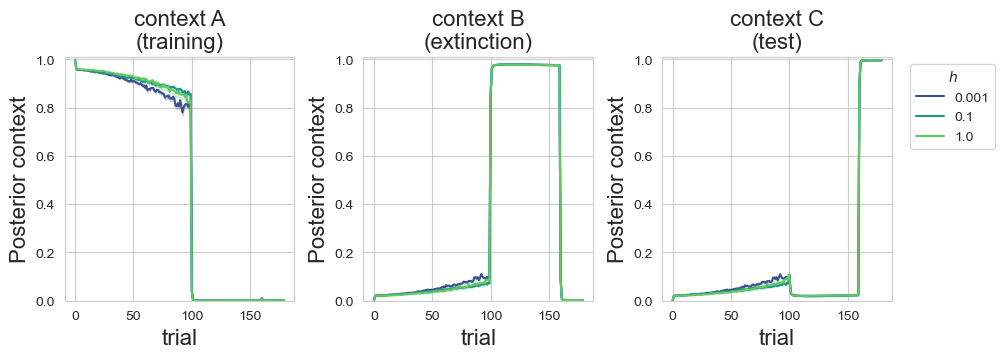

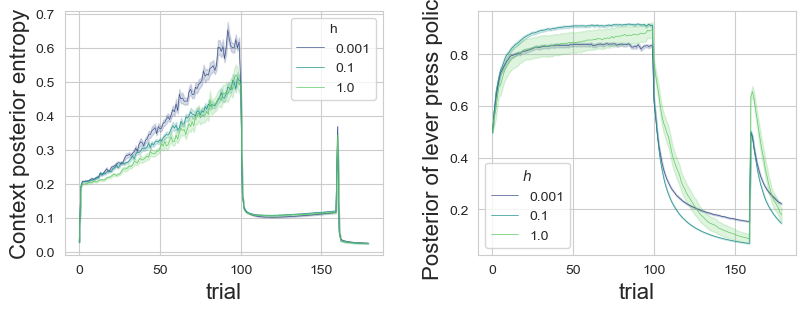

<Figure size 640x480 with 0 Axes>

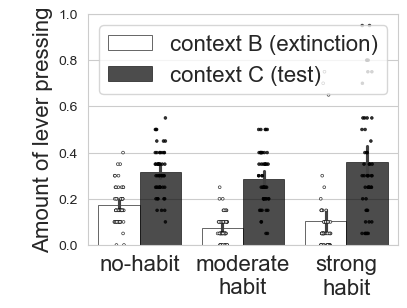

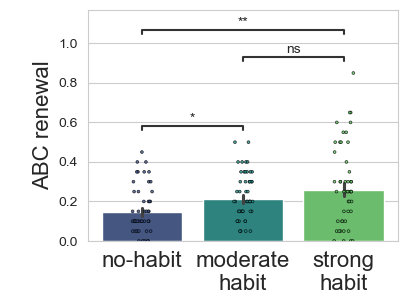

In [ ]:
dpi = 100

#############################################
# setup simulation run, agent, env parameters
############################################
np.random.seed(2)

h_order = ["no-habit", "moderate habit", "strong habit"]
env_order = ["low-certainty", "high-certainty"]

pars = {
	"na": 2,
	"nc": 3,
	"T":2,
	"nr":3,
	"hs": np.array([1,10,1000]),
	"context_volatility" : 0.75,
	"block_size" : 20,
	"utility" : np.array([0.025,0.95,0.025]),
	"nsims" : 50,
	"learn_cues" : True,
	"debug" : False,
}

pars["blocks_per_context"] = np.array([5,3,1])
pars["training_protocol"] = [[bi]*(nb*pars["block_size"]) for bi, nb in enumerate(pars["blocks_per_context"])]
pars["training_protocol"] = np.array([item for sublist in pars["training_protocol"] for item in sublist])
pars["nb"] = pars["na"]
pars["ns"] = pars["nb"] + 1
pars["no"] = pars["ns"]
pars["color_cue_context_mapping"] = np.eye(pars["ns"])
pars["npi"] = pars["na"]**(pars["T"]-1)
pars["TAU"] = pars["training_protocol"].size

prior_color_cue = np.array([[5,  1,  1],
							[1,  5,  1],
							[1,  1,  5]])

pars["prior_color_cue"] = prior_color_cue

Rho = np.zeros([pars["nr"], pars["ns"], pars["TAU"]])

p_win = 0.9
training = np.array([[1-p_win, p_win  , 0],\
					 [p_win  , 1-p_win, 0],\
					 [0      , 0      , 1]])

p_win = 1
extinction = np.array([ [p_win  , 1-p_win  , 0],\
						[1-p_win, 1, 0],\
						[0      , 0      , 1]])
pars["Rho"] = np.stack([training, extinction, extinction],axis=-1)
# pars["Rho"] = Rho[:,:,pars["training_protocol"]]


################################################
# create pars dictionary for each simulation run
################################################
utilities = np.array([pars["utility"]])
agent_instance = np.arange(pars["nsims"])
context_volatilities = np.array([pars["context_volatility"]])
blocks_per_context = np.array([pars["blocks_per_context"]])

## construct list of simulations
parameter_combinations = product(agent_instance, pars["hs"], utilities, blocks_per_context, context_volatilities)
sim_params = []

for pi, p in enumerate(parameter_combinations):
	# sim specific params
	par = pars.copy()
	par["rep"] = p[0]
	par["sim"] = pi
	par["h"] = p[1]
	par["utility"] = p[2]
	par["blocks_per_context"] = p[3]
	par["context_volatility"] = p[4]
	sim_params.append(par)


long_dfs = []
for pi, p in enumerate(sim_params):
	print(f"just finished sim {p["sim"]}") if pi% 250 == 0 else None
	world, _ , _ = run_simulation(**p)
	long_dfs.append(create_long_df_ABC(world, p))
	

name = f"data_ABC_{pars["TAU"]}_util{pars["utility"][0]}_context{pars["context_volatility"]}"
long_df = pd.concat(long_dfs)
long_df.to_csv(name + "_long.csv", index=False)
plot_figures(long_df.copy(), pars)
